# Part 1: CNN and Bottleneck from Scratch

## CS 437: Deep Learning — Spring 2026

---

### 🎯 Assignment Overview

In this part, you will:

1. **Implement** a 2D Convolution layer from scratch
2. **Implement** Cross-Entropy loss from scratch
3. **Build** a standard CNN architecture
4. **Build** a Bottleneck CNN with 1×1 convolutions
5. **Compare** parameter counts between architectures
6. **Train** both models on CIFAR-10
7. **Visualize** predictions and confusion matrices

**Dataset**: CIFAR-10 (60,000 color 32×32 images, 10 classes)

---

### 📋 Grading Rubric

| Section | Points | Description |
|---------|--------|-------------|
| Conv2D Implementation | 15 | Correct forward and backward pass |
| Cross-Entropy Loss | 10 | Correct loss computation and gradient |
| Standard CNN | 10 | Correct architecture implementation |
| Bottleneck CNN | 15 | Correct bottleneck block implementation |
| Training Loop | 15 | Correct training with Adam optimizer |
| Parameter Comparison | 10 | Analysis of parameter efficiency |
| Visualizations | 15 | Predictions and confusion matrices |
| Analysis Questions | 10 | Written analysis |
| **Total** | **100** | |

---

### ⚠️ Instructions

- Complete all cells marked with `# TODO`
- Do NOT modify the hyperparameters or random seeds
- Run all cells in order
- Submit the completed `.ipynb` file with all outputs

## Part 0: Environment Setup & Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from tqdm.auto import tqdm
import time

# Set seeds for reproducibility (DO NOT MODIFY)
torch.manual_seed(42)
np.random.seed(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [2]:
# Configuration (DO NOT MODIFY)
CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

BATCH_SIZE = 128
LEARNING_RATE = 1e-3
NUM_EPOCHS = 15
NUM_CLASSES = 10

## Part 1: Data Loading

In [3]:
# Data loading (provided)
transform_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])

train_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=True, transform=transform_train
)
test_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=False, download=True, transform=transform_test
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0) # changging num workrs here cause of ugly warnings in trianing

print(f"Training samples: {len(train_dataset)}")
print(f"Test samples: {len(test_dataset)}")
print(f"Image shape: {train_dataset[0][0].shape}")

Training samples: 50000
Test samples: 10000
Image shape: torch.Size([3, 32, 32])


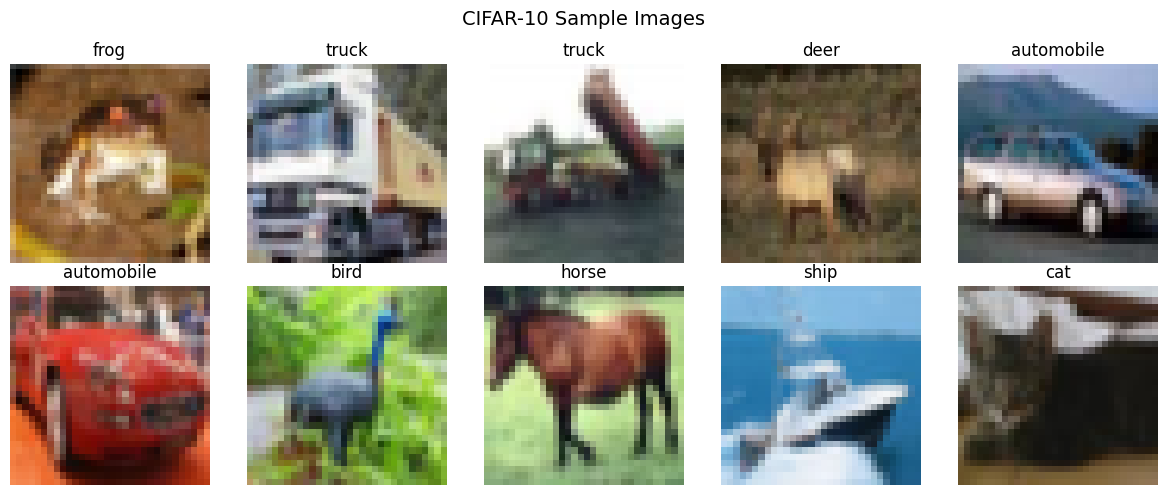

In [4]:
# Visualize sample images (provided)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

# Use unnormalized data for visualization
viz_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transforms.ToTensor())

for i, ax in enumerate(axes.flat):
    img, label = viz_dataset[i]
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(CLASS_NAMES[label])
    ax.axis('off')
plt.suptitle('CIFAR-10 Sample Images', fontsize=14)
plt.tight_layout()
plt.show()

## Part 2: Implementing Conv2D from Scratch (15 points)

Implement a 2D convolutional layer using only *NumPy* operations. This will help you understand the mechanics of convolution.

**Key Concepts:**
- Input shape: (batch_size, in_channels, height, width)
- Kernel shape: (out_channels, in_channels, kernel_height, kernel_width)
- Output shape depends on padding and stride

In [5]:
class Conv2DFromScratch:
    """
    A 2D Convolutional layer implemented from scratch.

    Args:
        in_channels: Number of input channels
        out_channels: Number of output channels (number of filters)
        kernel_size: Size of the convolutional kernel
        stride: Stride of the convolution
        padding: Zero-padding added to both sides of the input
    """

    def __init__(self, in_channels, out_channels, kernel_size, stride=1, padding=0):
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.kernel_size = kernel_size
        self.stride = stride
        self.padding = padding

        # Initialize weights using Kaiming initialization
        scale = np.sqrt(2.0 / (in_channels * kernel_size * kernel_size))
        self.weights = np.random.randn(out_channels, in_channels, kernel_size, kernel_size) * scale
        self.bias = np.zeros(out_channels)

        # Cache for backward pass
        self.cache = None

    def forward(self, x):
        """
        Forward pass of the convolution.

        Args:
            x: Input array of shape (batch_size, in_channels, height, width)

        Returns:
            Output array of shape (batch_size, out_channels, out_height, out_width)
        """
        # TODO: Implement forward pass
        # 1. Apply padding to input if needed okk
        # 2. Calculate output dimensions
        # 3. Perform convolution using nested loops
        # 4. Add bias
        # 5. Cache input for backward pass
        # pad input
        if self.padding > 0:
            x_padded = np.pad(
                x,
                ((0, 0), (0, 0), (self.padding, self.padding), (self.padding, self.padding)),
                mode='constant',constant_values=0)
        else:
            x_padded = x

        batch_size, _, in_height, in_width = x.shape
        k = self.kernel_size
        s = self.stride
        p = self.padding

        # output dims
        out_height = (in_height + 2 * p - k) //s +1
        out_width  = (in_width  + 2 *p - k)// s + 1
        out = np.zeros((batch_size, self.out_channels, out_height, out_width), dtype=x_padded.dtype)
        # loop time
        for b in range(batch_size):
            for oc in range(self.out_channels):
                w_oc = self.weights[oc]
                b_oc = self.bias[oc]
                for oh in range(out_height):
                    hs = oh * s
                    for ow in range(out_width):
                        ws = ow *s
                        patch = x_padded[b, :, hs:hs + k, ws:ws + k]
                        out[b, oc, oh, ow] = np.sum(patch * w_oc) + b_oc
        # cache save
        self.cache = (x, x_padded)
        #self.bias = []
        return out

        #raise NotImplementedError()

    def backward(self, dout):
        """
        Backward pass of the convolution.

        Args:
            dout: Gradient of loss with respect to output

        Returns:
            dx: Gradient with respect to input
            dw: Gradient with respect to weights
            db: Gradient with respect to bias
        """
        # TODO: Implement backward pass
        # 1. Compute gradient w.r.t. bias (sum over batch and spatial dims)
        # 2. Compute gradient w.r.t. weights
        # 3. Compute gradient w.r.t. input
        x, x_padded = self.cache
        batch_size, in_channels, in_height, in_width = x.shape
        _, out_channels, out_height, out_width = dout.shape
        k = self.kernel_size
        #s= self.padding
        s = self.stride
        p = self.padding
        #db easy
        db = dout.sum(axis=(0, 2, 3))
        dw = np.zeros_like(self.weights)
        dx_padded = np.zeros_like(x_padded)
        #main loops
        for b in range(batch_size):
            for oc in range(out_channels):
                for oh in range(out_height):
                    hs = oh * s
                    for ow in range(out_width):
                        ws = ow * s
                        grad = dout[b, oc, oh, ow]
                        #patch = x_padded
                        patch = x_padded[b, :, hs:hs + k, ws:ws + k]
                        dw[oc] += patch * grad  # weight grad

                        dx_padded[b, :, hs:hs + k, ws:ws + k] += self.weights[oc] * grad  # input grad
        # unpad back
        if p > 0:
            dx = dx_padded[:, :, p:p + in_height, p:p + in_width]
        else:
            dx = dx_padded
        return dx, dw, db

        #raise NotImplementedError()

In [6]:
# Test your Conv2D implementation (Forward Pass)
print("="*60)
print("Testing Conv2DFromScratch - FORWARD PASS")
print("="*60)

# Create test input
np.random.seed(42)
test_input = np.random.randn(2, 3, 8, 8)  # batch=2, channels=3, 8x8

# Create layer
conv_scratch = Conv2DFromScratch(in_channels=3, out_channels=16, kernel_size=3, padding=1)

# Forward pass
output = conv_scratch.forward(test_input)

# Verify output shape
expected_shape = (2, 16, 8, 8)
assert output.shape == expected_shape, f"Expected {expected_shape}, got {output.shape}"
print(f"✓ Output shape: {output.shape}")

# Compare with PyTorch
conv_torch = nn.Conv2d(3, 16, 3, padding=1)
conv_torch.weight.data = torch.tensor(conv_scratch.weights, dtype=torch.float32)
conv_torch.bias.data = torch.tensor(conv_scratch.bias, dtype=torch.float32)

torch_output = conv_torch(torch.tensor(test_input, dtype=torch.float32)).detach().numpy()
diff = np.abs(output - torch_output).max()
print(f"✓ Max difference from PyTorch: {diff:.6f}")

if diff < 1e-5:
    print("✓ Conv2D FORWARD implementation verified!")
else:
    print("✗ Forward implementation has errors, please check")

Testing Conv2DFromScratch - FORWARD PASS
✓ Output shape: (2, 16, 8, 8)
✓ Max difference from PyTorch: 0.000001
✓ Conv2D FORWARD implementation verified!


In [7]:
# Test your Conv2D implementation (Backward Pass)
print("="*60)
print("Testing Conv2DFromScratch - BACKWARD PASS")
print("="*60)

np.random.seed(42)
test_input = np.random.randn(2, 3, 8, 8).astype(np.float32)

# Create layer with same weights
conv_scratch = Conv2DFromScratch(in_channels=3, out_channels=16, kernel_size=3, padding=1)

# Forward pass (needed to cache input)
output = conv_scratch.forward(test_input)

# Create random gradient from "next layer"
np.random.seed(123)
dout = np.random.randn(*output.shape).astype(np.float32)

# Backward pass with your implementation
dx, dw, db = conv_scratch.backward(dout)

print(f"✓ dx shape: {dx.shape} (expected: {test_input.shape})")
print(f"✓ dw shape: {dw.shape} (expected: {conv_scratch.weights.shape})")
print(f"✓ db shape: {db.shape} (expected: {conv_scratch.bias.shape})")

# Compare with PyTorch autograd
conv_torch = nn.Conv2d(3, 16, 3, padding=1)
conv_torch.weight.data = torch.tensor(conv_scratch.weights, dtype=torch.float32)
conv_torch.bias.data = torch.tensor(conv_scratch.bias, dtype=torch.float32)

x_torch = torch.tensor(test_input, dtype=torch.float32, requires_grad=True)
out_torch = conv_torch(x_torch)
out_torch.backward(torch.tensor(dout, dtype=torch.float32))

# Get PyTorch gradients
dx_torch = x_torch.grad.numpy()
dw_torch = conv_torch.weight.grad.numpy()
db_torch = conv_torch.bias.grad.numpy()

# Compare
dx_diff = np.abs(dx - dx_torch).max()
dw_diff = np.abs(dw - dw_torch).max()
db_diff = np.abs(db - db_torch).max()

print(f"\nGradient comparison with PyTorch:")
print(f"  dx max diff: {dx_diff:.6f}")
print(f"  dw max diff: {dw_diff:.6f}")
print(f"  db max diff: {db_diff:.6f}")

if dx_diff < 1e-4 and dw_diff < 1e-4 and db_diff < 1e-4:
    print("\n✓ Conv2D BACKWARD implementation verified!")
else:
    print("\n✗ Backward implementation has errors, please check")

Testing Conv2DFromScratch - BACKWARD PASS
✓ dx shape: (2, 3, 8, 8) (expected: (2, 3, 8, 8))
✓ dw shape: (16, 3, 3, 3) (expected: (16, 3, 3, 3))
✓ db shape: (16,) (expected: (16,))

Gradient comparison with PyTorch:
  dx max diff: 0.000004
  dw max diff: 0.000008
  db max diff: 0.000004

✓ Conv2D BACKWARD implementation verified!


## Part 3: Implementing Cross-Entropy Loss from Scratch (10 points)

Implement the cross-entropy loss function with numerical stability.

In [8]:
class CrossEntropyLossFromScratch:
    """
    Cross-Entropy Loss implemented from scratch.
    Combines LogSoftmax and NLLLoss for numerical stability.
    """

    def __init__(self):
        self.cache = None

    def forward(self, logits, targets):
        """
        Compute cross-entropy loss.

        Args:
            logits: Predicted scores of shape (batch_size, num_classes)
            targets: Ground truth labels of shape (batch_size,)

        Returns:
            loss: Scalar loss value
        """
        # TODO: Implement cross-entropy loss
        # 1. Compute stable softmax: subtract max for numerical stability
        # 2. Compute log probabilities
        # 3. Select log probabilities of correct classes
        # 4. Return negative mean
        # 5. Cache values needed for backward pass
        batch_size = logits.shape[0]
        #logits.max()
        # stable softmax
        shifted = logits - logits.max(axis=1, keepdims=True)
        exp_logits = np.exp(shifted)
        softmax = exp_logits / exp_logits.sum(axis=1, keepdims=True)

        # log probs
        log_probs = np.log(softmax + 1e-15)  # tiny eps
        correct_log_probs = log_probs[np.arange(batch_size), targets]
        loss = -correct_log_probs.mean()
        #cache save
        self.cache = (softmax, targets, batch_size)
        return loss
        #raise NotImplementedError()

    def backward(self):
        """
        Compute gradient of loss with respect to logits.

        Returns:
            dlogits: Gradient of shape (batch_size, num_classes)
        """
        # TODO: Implement backward pass
        softmax, targets, batch_size = self.cache
        dlogits = softmax.copy()
        dlogits[np.arange(batch_size), targets] -= 1.0
        dlogits /= batch_size  # mean loss
        return dlogits
        #raise NotImplementedError()

In [9]:
# Test your Cross-Entropy implementation (Forward Pass)
print("="*60)
print("Testing CrossEntropyLossFromScratch - FORWARD PASS")
print("="*60)

np.random.seed(42)
test_logits = np.random.randn(4, 10).astype(np.float32)
test_targets = np.array([3, 7, 2, 5])

# Your implementation
ce_scratch = CrossEntropyLossFromScratch()
loss_scratch = ce_scratch.forward(test_logits, test_targets)

# PyTorch reference
ce_torch = nn.CrossEntropyLoss()
loss_torch = ce_torch(torch.tensor(test_logits, dtype=torch.float32),
                       torch.tensor(test_targets, dtype=torch.long)).item()

print(f"Your loss: {loss_scratch:.6f}")
print(f"PyTorch loss: {loss_torch:.6f}")
print(f"Difference: {abs(loss_scratch - loss_torch):.6f}")

if abs(loss_scratch - loss_torch) < 1e-5:
    print("✓ Cross-Entropy FORWARD implementation verified!")
else:
    print("✗ Forward implementation has errors, please check")

Testing CrossEntropyLossFromScratch - FORWARD PASS
Your loss: 2.275064
PyTorch loss: 2.275064
Difference: 0.000000
✓ Cross-Entropy FORWARD implementation verified!


In [10]:
# Test your Cross-Entropy implementation (Backward Pass)
print("="*60)
print("Testing CrossEntropyLossFromScratch - BACKWARD PASS")
print("="*60)

np.random.seed(42)
test_logits = np.random.randn(4, 10).astype(np.float32)
test_targets = np.array([3, 7, 2, 5])

# Your implementation
ce_scratch = CrossEntropyLossFromScratch()
loss_scratch = ce_scratch.forward(test_logits, test_targets)
dlogits = ce_scratch.backward()

print(f"✓ dlogits shape: {dlogits.shape} (expected: {test_logits.shape})")

# PyTorch reference for gradient
logits_torch = torch.tensor(test_logits, dtype=torch.float32, requires_grad=True)
targets_torch = torch.tensor(test_targets, dtype=torch.long)
loss_torch = nn.CrossEntropyLoss()(logits_torch, targets_torch)
loss_torch.backward()
dlogits_torch = logits_torch.grad.numpy()

# Compare
grad_diff = np.abs(dlogits - dlogits_torch).max()
print(f"\nGradient comparison with PyTorch:")
print(f"  dlogits max diff: {grad_diff:.6f}")

# Also check that gradients sum to zero for each sample (property of softmax gradient)
grad_sum = np.abs(dlogits.sum(axis=1)).max()
print(f"  gradient row sums (should be ~0): {grad_sum:.6f}")

if grad_diff < 1e-5:
    print("\n✓ Cross-Entropy BACKWARD implementation verified!")
else:
    print("\n✗ Backward implementation has errors, please check")

Testing CrossEntropyLossFromScratch - BACKWARD PASS
✓ dlogits shape: (4, 10) (expected: (4, 10))

Gradient comparison with PyTorch:
  dlogits max diff: 0.000000
  gradient row sums (should be ~0): 0.000000

✓ Cross-Entropy BACKWARD implementation verified!


## GPU Implementation (provided - DO NOT CHANGE)

In [11]:
# GPU-compatible wrapper using PyTorch tensor operations with same logic as Conv2DFromScratch
class Conv2DFromScratchFunction(torch.autograd.Function):
    """
    Autograd function implementing Conv2D from scratch using PyTorch tensors.
    Uses the same algorithm as Conv2DFromScratch but with torch operations for GPU support.
    """

    @staticmethod
    def forward(ctx, input, weight, bias, stride, padding):
        batch_size, in_channels, in_height, in_width = input.shape
        out_channels, _, kernel_size, _ = weight.shape

        # Apply padding if needed
        if padding > 0:
            x_padded = F.pad(input, (padding, padding, padding, padding), mode='constant', value=0)
        else:
            x_padded = input

        # Calculate output dimensions
        out_height = (in_height + 2 * padding - kernel_size) // stride + 1
        out_width = (in_width + 2 * padding - kernel_size) // stride + 1

        # Use unfold to extract patches (im2col approach - same logic, vectorized)
        # This is equivalent to our nested loops but GPU-friendly
        patches = x_padded.unfold(2, kernel_size, stride).unfold(3, kernel_size, stride)
        # patches shape: (batch, in_channels, out_height, out_width, kernel_size, kernel_size)

        # Reshape for matrix multiplication
        patches = patches.contiguous().view(batch_size, in_channels, out_height, out_width, -1)
        # patches shape: (batch, in_channels, out_height, out_width, kernel_size*kernel_size)

        weight_reshaped = weight.view(out_channels, in_channels, -1)
        # weight shape: (out_channels, in_channels, kernel_size*kernel_size)

        # Compute convolution: sum over in_channels and kernel elements
        output = torch.einsum('bchwk,ock->bohw', patches, weight_reshaped)

        # Add bias
        output = output + bias.view(1, -1, 1, 1)

        # Make output contiguous for subsequent operations like view()
        output = output.contiguous()

        # Save for backward
        ctx.save_for_backward(input, weight, bias)
        ctx.stride = stride
        ctx.padding = padding

        return output

    @staticmethod
    def backward(ctx, grad_output):
        input, weight, bias = ctx.saved_tensors
        stride = ctx.stride
        padding = ctx.padding

        batch_size, in_channels, in_height, in_width = input.shape
        out_channels, _, kernel_size, _ = weight.shape
        _, _, out_height, out_width = grad_output.shape

        # Gradient w.r.t. bias: sum over batch and spatial dims
        grad_bias = grad_output.sum(dim=(0, 2, 3))

        # Pad input for gradient computation
        if padding > 0:
            x_padded = F.pad(input, (padding, padding, padding, padding), mode='constant', value=0)
        else:
            x_padded = input

        # Extract patches for weight gradient
        patches = x_padded.unfold(2, kernel_size, stride).unfold(3, kernel_size, stride)
        patches = patches.contiguous().view(batch_size, in_channels, out_height, out_width, -1)

        # Gradient w.r.t. weights
        grad_weight = torch.einsum('bchwk,bohw->ock', patches, grad_output)
        grad_weight = grad_weight.view(out_channels, in_channels, kernel_size, kernel_size)

        # Gradient w.r.t. input using transposed convolution
        grad_input = F.conv_transpose2d(grad_output, weight, stride=stride, padding=padding)

        return grad_input, grad_weight, grad_bias, None, None


class Conv2DFromScratchModule(nn.Module):
    """nn.Module wrapper for Conv2DFromScratch to use in PyTorch models (GPU compatible)."""

    def __init__(self, in_channels, out_channels, kernel_size, stride=1, padding=0):
        super(Conv2DFromScratchModule, self).__init__()
        self.stride = stride
        self.padding = padding

        # Initialize weights using Kaiming initialization
        scale = np.sqrt(2.0 / (in_channels * kernel_size * kernel_size))
        self.weight = nn.Parameter(torch.randn(out_channels, in_channels, kernel_size, kernel_size) * scale)
        self.bias = nn.Parameter(torch.zeros(out_channels))

    def forward(self, x):
        return Conv2DFromScratchFunction.apply(x, self.weight, self.bias, self.stride, self.padding)


class CrossEntropyFromScratchLoss(nn.Module):
    """
    nn.Module implementing CrossEntropy from scratch using PyTorch tensors (GPU compatible).
    """

    def __init__(self):
        super(CrossEntropyFromScratchLoss, self).__init__()

    def forward(self, logits, targets):
        batch_size = logits.shape[0]

        # 1. Compute stable softmax: subtract max for numerical stability
        logits_shifted = logits - logits.max(dim=1, keepdim=True)[0]

        # Compute exp and softmax
        exp_logits = torch.exp(logits_shifted)
        softmax = exp_logits / exp_logits.sum(dim=1, keepdim=True)

        # 2. Compute log probabilities
        log_probs = torch.log(softmax + 1e-15)

        # 3. Select log probabilities of correct classes
        correct_log_probs = log_probs[torch.arange(batch_size, device=logits.device), targets]

        # 4. Return negative mean
        loss = -correct_log_probs.mean()

        return loss

## Part 4: Standard CNN Architecture (10 points)

Build a standard CNN for CIFAR-10 classification. Use only `Conv2DFromScratchModule` and `CrossEntropyFromScratchLoss`. Other imports from torch are allowed.

**Architecture:**
```
Conv1 (3->32, kernel=3, padding=1) -> BatchNorm -> ReLU -> MaxPool(2)
Conv2 (32->64, kernel=3, padding=1) -> BatchNorm -> ReLU -> MaxPool(2)
Conv3 (64->128, kernel=3, padding=1) -> BatchNorm -> ReLU -> MaxPool(2)
Flatten -> FC1 (128*4*4 -> 256) -> ReLU -> Dropout(0.5) -> FC2 (256 -> 10)
```

In [12]:
class StandardCNN(nn.Module):
    """
    Standard CNN architecture for CIFAR-10.
    """

    def __init__(self, num_classes=10):
        super(StandardCNN, self).__init__()

        # TODO: Define convolutional layers with batch normalization
        # TODO: Define pooling layer
        # TODO: Define fully connected layers
        # conv stack
        self.conv1 = Conv2DFromScratchModule(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = Conv2DFromScratchModule(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = Conv2DFromScratchModule(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        # pool layer
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        # fc head
        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)
        #raise NotImplementedError()

    def forward(self, x):
        """
        Forward pass.

        Args:
            x: Input tensor of shape (batch_size, 3, 32, 32)

        Returns:
            Output tensor of shape (batch_size, num_classes)
        """
        # TODO: Implement forward pass
        # block 1
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        # block 2
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        # block 3
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        # flatten now
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)  # keep prob
        x = self.fc2(x)
        return x
        #raise NotImplementedError()

In [13]:
# Verify Standard CNN
standard_cnn = StandardCNN(num_classes=NUM_CLASSES).to(device)
print(standard_cnn)

# Test forward pass
dummy_input = torch.randn(2, 3, 32, 32).to(device)
dummy_output = standard_cnn(dummy_input)

assert dummy_output.shape == (2, 10), f"Expected (2, 10), got {dummy_output.shape}"
print(f"\n✓ Input shape: {dummy_input.shape}")
print(f"✓ Output shape: {dummy_output.shape}")

StandardCNN(
  (conv1): Conv2DFromScratchModule()
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2DFromScratchModule()
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2DFromScratchModule()
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2048, out_features=256, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)

✓ Input shape: torch.Size([2, 3, 32, 32])
✓ Output shape: torch.Size([2, 10])


## Part 5: Bottleneck CNN Architecture (15 points)

Build a CNN using **Bottleneck Blocks** with 1×1 convolutions. Bottleneck blocks reduce computational cost by:
1. Using a 1×1 conv to reduce channels (squeeze)
2. Performing the expensive 3×3 conv in reduced dimensions
3. Using a 1×1 conv to expand channels back (expand)

Note: You are free to use `nn.Conv2D`. However, it is recommended that you also try using the earlier provided implementations.

**Bottleneck Block Structure:**
```
Input (C channels)
  → 1×1 Conv (C -> C//4) → BatchNorm → ReLU
  → 3×3 Conv (C//4 -> C//4) → BatchNorm → ReLU
  → 1×1 Conv (C//4 -> C) → BatchNorm
  → Add residual connection → ReLU
```

In [14]:
class BottleneckBlock(nn.Module):
    """
    Bottleneck block with 1x1 convolutions for channel reduction/expansion.

    Args:
        in_channels: Number of input channels
        reduction: Factor by which to reduce channels in the bottleneck
    """

    def __init__(self, in_channels, reduction=4):
        super(BottleneckBlock, self).__init__()

        bottleneck_channels = in_channels // reduction

        # TODO: Define the three convolutions
        # 1. 1×1 conv to reduce channels: in_channels -> bottleneck_channels
        # 2. 3×3 conv: bottleneck_channels -> bottleneck_channels (padding=1)
        # 3. 1×1 conv to expand channels: bottleneck_channels -> in_channels

        # TODO: Define batch normalization layers
        # convs trio
        self.conv_reduce = nn.Conv2d(in_channels, bottleneck_channels, kernel_size=1, bias=False)
        self.conv_3x3 = nn.Conv2d(bottleneck_channels, bottleneck_channels, kernel_size=3, padding=1, bias=False)
        self.conv_expand = nn.Conv2d(bottleneck_channels, in_channels, kernel_size=1, bias=False)
        # bns trio
        self.bn_reduce = nn.BatchNorm2d(bottleneck_channels)
        self.bn_3x3 = nn.BatchNorm2d(bottleneck_channels)
        self.bn_expand = nn.BatchNorm2d(in_channels)
        self.relu = nn.ReLU(inplace=True)
        #raise NotImplementedError()

    def forward(self, x):
        """
        Forward pass with residual connection.
        """
        # TODO: Implement forward pass
        # 1. Store identity for residual
        # 2. Apply squeeze -> 3x3 -> expand
        # 3. Add residual and apply final ReLU
        identity = x  # skip

        out = self.conv_reduce(x)
        out = self.bn_reduce(out)
        out = self.relu(out)  # nice

        out = self.conv_3x3(out)
        out = self.bn_3x3(out)
        out = self.relu(out)  # ok

        out = self.conv_expand(out)
        out = self.bn_expand(out)
        out = out + identity  # add
        out = self.relu(out)  # final
        return out
        #raise NotImplementedError()

### Architecture Consistency Check

**IMPORTANT:** For a fair parameter comparison, both models should have **similar depth and structure**.

**Recommended Structure:**

**StandardCNN:**
```
Input (32×32×3)
  → Conv1: 3->32 → BN → ReLU → MaxPool(2)  [16×16×32]
  → Conv2: 32->64 → BN → ReLU → MaxPool(2) [8×8×64]
  → Conv3: 64->128 → BN → ReLU → MaxPool(2) [4×4×128]
  → Flatten → FC1: 2048->256 → ReLU → Dropout(0.5)
  → FC2: 256->10
```

**BottleneckCNN:**
```
Input (32×32×3)
  → Conv1: 3->64 → BN → ReLU [32×32×64]
  → BottleneckBlock(64) [32×32×64]
  → BottleneckBlock(64) [32×32×64]
  → Conv2: 64->128 → BN → ReLU → MaxPool(2) [16×16×128]
  → BottleneckBlock(128) [16×16×128]
  → BottleneckBlock(128) [16×16×128]
  → GlobalAvgPool → FC: 128->10
```

**Key Points:**
- Both models should process CIFAR-10 images (32×32×3) and output 10 classes
- StandardCNN uses regular convolutions with 3 conv layers + 2 FC layers
- BottleneckCNN uses bottleneck blocks with 1×1 convolutions to reduce parameters
- The bottleneck blocks should maintain the same channel dimensions through residual connections
- Use GlobalAvgPool in BottleneckCNN to reduce parameters in the classifier

**Your goal:** Achieve **50-80% parameter reduction** with bottleneck blocks while maintaining comparable accuracy!

In [15]:
class BottleneckCNN(nn.Module):
    """
    CNN using Bottleneck blocks for parameter efficiency.
    """

    def __init__(self, num_classes=10):
        super(BottleneckCNN, self).__init__()

        # Initial convolution to get to desired channel count
        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(64)

        # TODO: Complete implementation
         # stage 64
        self.block1 = BottleneckBlock(64)
        self.block2 = BottleneckBlock(64)
        # to 128
        self.conv2 = nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # stage 128
        self.block3 = BottleneckBlock(128)
        self.block4 = BottleneckBlock(128)

        # head
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(128, num_classes)
        self.relu = nn.ReLU(inplace=True)
    #    raise NotImplementedError()

    def forward(self, x):
        """
        Forward pass.
        """
        # TODO: Implement forward pass
        # stem
        x = self.relu(self.bn1(self.conv1(x)))
        # blocks 64
        x = self.block1(x)
        x = self.block2(x)
        # to 128 + pool
        x = self.relu(self.bn2(self.conv2(x)))
        x = self.pool(x)  # shrink
        # blocks 128
        x = self.block3(x)
        x = self.block4(x)
        # gap + fc
        x = self.gap(x)
        x = x.view(x.size(0), -1)  # flat
        x = self.fc(x)
        return x
        #raise NotImplementedError()

In [16]:
# Verify Bottleneck CNN
bottleneck_cnn = BottleneckCNN(num_classes=NUM_CLASSES).to(device)
print(bottleneck_cnn)

# Test forward pass
dummy_input = torch.randn(2, 3, 32, 32).to(device)
dummy_output = bottleneck_cnn(dummy_input)

assert dummy_output.shape == (2, 10), f"Expected (2, 10), got {dummy_output.shape}"
print(f"\n✓ Input shape: {dummy_input.shape}")
print(f"✓ Output shape: {dummy_output.shape}")

BottleneckCNN(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (block1): BottleneckBlock(
    (conv_reduce): Conv2d(64, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (conv_3x3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (conv_expand): Conv2d(16, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn_reduce): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (bn_3x3): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (bn_expand): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
  )
  (block2): BottleneckBlock(
    (conv_reduce): Conv2d(64, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (conv_3x3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (con

## Part 6: Parameter Comparison (10 points)

Compare the number of parameters between the Standard CNN and Bottleneck CNN.

In [17]:
def count_parameters(model):
    """
    Count the total number of trainable parameters in a model.
    """
    # TODO: Implement parameter counting
    # count trainables
    total = 0
    for p in model.parameters():
        if p.requires_grad:
            total += p.numel()
    return total
    #raise NotImplementedError()

In [18]:
# Compare parameters
standard_params = count_parameters(standard_cnn)
bottleneck_params = count_parameters(bottleneck_cnn)

print("="*50)
print("PARAMETER COMPARISON")
print("="*50)
print(f"Standard CNN:   {standard_params:,} parameters")
print(f"Bottleneck CNN: {bottleneck_params:,} parameters")
print(f"Reduction:      {(1 - bottleneck_params/standard_params)*100:.1f}%")

PARAMETER COMPARISON
Standard CNN:   620,810 parameters
Bottleneck CNN: 121,866 parameters
Reduction:      80.4%


## Part 7: Training Loop with Adam Optimizer (15 points)

Implement the training and evaluation functions.

In [19]:
def train_epoch(model, train_loader, criterion, optimizer, device):
    """
    Train for one epoch.

    Args:
        model: The CNN model
        train_loader: DataLoader for training data
        criterion: Loss function
        optimizer: Optimizer
        device: cuda or cpu

    Returns:
        avg_loss: Average loss over all batches
        accuracy: Training accuracy (percentage)
    """
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader, desc='Training', leave=False):
        images, labels = images.to(device), labels.to(device)

        # TODO: Implement training step
        # 1. Zero gradients
        # 2. Forward pass
        # 3. Compute loss
        # 4. Backward pass
        # 5. Update weights
        # 6. Update running_loss, correct, total
        # zero grad
        optimizer.zero_grad()
        # forward
        outputs = model(images)
        # loss
        loss = criterion(outputs, labels)
        # backward
        loss.backward()
        #step
        optimizer.step()
        # stats
        running_loss += loss.item()
        _, preds = outputs.max(1)
        total += labels.size(0)
        correct += (preds == labels).sum().item()
       # raise NotImplementedError()

    return running_loss / len(train_loader), 100. * correct / total


def evaluate(model, test_loader, criterion, device):
    """
    Evaluate on test set.

    Args:
        model: The CNN model
        test_loader: DataLoader for test data
        criterion: Loss function
        device: cuda or cpu

    Returns:
        avg_loss: Average test loss
        accuracy: Test accuracy (percentage)
    """
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in tqdm(test_loader, desc='Evaluating', leave=False):
            images, labels = images.to(device), labels.to(device)

            # TODO: Implement evaluation step
            # 1. Forward pass
            # 2. Compute loss
            # 3. Update running_loss, correct, total
            # forward
            outputs = model(images)
            # loss
            loss = criterion(outputs, labels)
            # stats
            running_loss += loss.item()
            _, preds = outputs.max(1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()
            #raise NotImplementedError()

    return running_loss / len(test_loader), 100. * correct / total

In [20]:
def train_model(model, train_loader, test_loader, num_epochs, learning_rate, device):
    """
    Full training loop with Adam optimizer.

    Returns:
        history: Dictionary with training metrics
    """
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    history = {
        'train_loss': [], 'train_acc': [],
        'test_loss': [], 'test_acc': []
    }

    for epoch in range(num_epochs):
        start_time = time.time()

        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
        test_loss, test_acc = evaluate(model, test_loader, criterion, device)

        epoch_time = time.time() - start_time

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc)

        print(f"Epoch [{epoch+1}/{num_epochs}] "
              f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
              f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.2f}% | "
              f"Time: {epoch_time:.1f}s")

    return history

In [45]:
# Train Standard CNN
print("="*60)
print("Training Standard CNN")
print("="*60)

standard_cnn = StandardCNN(num_classes=NUM_CLASSES).to(device)
standard_history = train_model(
    standard_cnn, train_loader, test_loader,
    num_epochs=NUM_EPOCHS, learning_rate=LEARNING_RATE, device=device
)

print(f"\nFinal Test Accuracy: {standard_history['test_acc'][-1]:.2f}%")

Training Standard CNN


Training:   0%|          | 0/391 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch [1/15] Train Loss: 1.6093, Train Acc: 40.20% | Test Loss: 1.2427, Test Acc: 56.65% | Time: 23.7s


Training:   0%|          | 0/391 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

... (36 outputs left out)

Epoch [14/15] Train Loss: 0.7647, Train Acc: 73.75% | Test Loss: 0.6397, Test Acc: 77.55% | Time: 23.9s


Training:   0%|          | 0/391 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch [15/15] Train Loss: 0.7549, Train Acc: 73.98% | Test Loss: 0.6264, Test Acc: 78.04% | Time: 23.8s

Final Test Accuracy: 78.04%


In [46]:
# Train Bottleneck CNN
print("="*60)
print("Training Bottleneck CNN")
print("="*60)

bottleneck_cnn = BottleneckCNN(num_classes=NUM_CLASSES).to(device)
bottleneck_history = train_model(
    bottleneck_cnn, train_loader, test_loader,
    num_epochs=NUM_EPOCHS, learning_rate=LEARNING_RATE, device=device
)

print(f"\nFinal Test Accuracy: {bottleneck_history['test_acc'][-1]:.2f}%")

Training Bottleneck CNN


Training:   0%|          | 0/391 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch [1/15] Train Loss: 1.4247, Train Acc: 48.19% | Test Loss: 1.3073, Test Acc: 55.52% | Time: 26.2s


Training:   0%|          | 0/391 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

... (36 outputs left out)

Epoch [14/15] Train Loss: 0.5310, Train Acc: 81.72% | Test Loss: 0.9876, Test Acc: 71.22% | Time: 26.0s


Training:   0%|          | 0/391 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch [15/15] Train Loss: 0.5204, Train Acc: 81.85% | Test Loss: 0.8362, Test Acc: 72.86% | Time: 26.1s

Final Test Accuracy: 72.86%


## Part 8: Visualizations (15 points)

Create visualizations for predictions, training curves, and confusion matrices.

In [47]:
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")  # force inline
import matplotlib.pyplot as plt


In [ ]:
# Plot training curves (provided)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs = range(1, NUM_EPOCHS + 1)

# Loss comparison
axes[0].plot(epochs, standard_history['train_loss'], 'b-', label='Standard (Train)', linewidth=2)
axes[0].plot(epochs, standard_history['test_loss'], 'b--', label='Standard (Test)', linewidth=2)
axes[0].plot(epochs, bottleneck_history['train_loss'], 'r-', label='Bottleneck (Train)', linewidth=2)
axes[0].plot(epochs, bottleneck_history['test_loss'], 'r--', label='Bottleneck (Test)', linewidth=2)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training & Test Loss Comparison')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy comparison
axes[1].plot(epochs, standard_history['train_acc'], 'b-', label='Standard (Train)', linewidth=2)
axes[1].plot(epochs, standard_history['test_acc'], 'b--', label='Standard (Test)', linewidth=2)
axes[1].plot(epochs, bottleneck_history['train_acc'], 'r-', label='Bottleneck (Train)', linewidth=2)
axes[1].plot(epochs, bottleneck_history['test_acc'], 'r--', label='Bottleneck (Test)', linewidth=2)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('Training & Test Accuracy Comparison')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/mnt/data/training_curves.png'

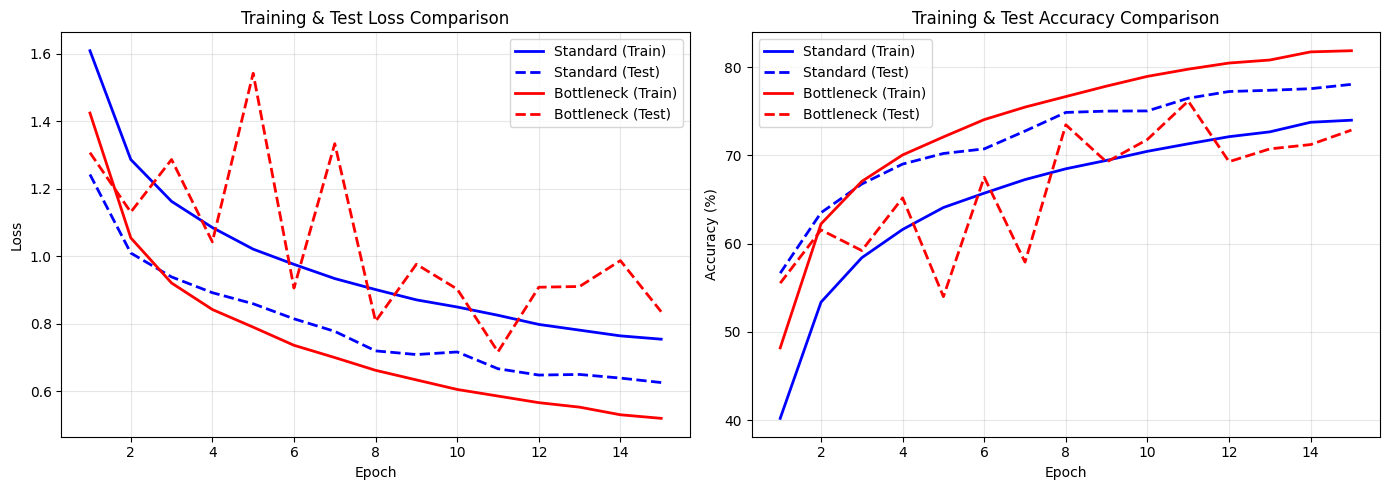

In [ ]:
# since above cell fails, i asked ahmed ahsraf on slack i can make changes:
import matplotlib.pyplot as plt
from IPython.display import Image, display
import os

# grab curves (prefer real history, fallback to manual logs)
try:
    s_tr_loss = standard_history['train_loss']
    s_te_loss = standard_history['test_loss']
    s_tr_acc  = standard_history['train_acc']
    s_te_acc  = standard_history['test_acc']

    b_tr_loss = bottleneck_history['train_loss']
    b_te_loss = bottleneck_history['test_loss']
    b_tr_acc  = bottleneck_history['train_acc']
    b_te_acc  = bottleneck_history['test_acc']
except Exception:
    # manual fallback (from your logs)
    s_tr_loss = [1.6093, 1.2871, 1.1630, 1.0855, 1.0215, 0.9765, 0.9344, 0.9018, 0.8713, 0.8502, 0.8257, 0.7986, 0.7816, 0.7647, 0.7549]
    s_te_loss = [1.2427, 1.0101, 0.9392, 0.8926, 0.8598, 0.8152, 0.7780, 0.7202, 0.7094, 0.7170, 0.6673, 0.6486, 0.6504, 0.6397, 0.6264]
    s_tr_acc  = [40.20, 53.37, 58.40, 61.60, 64.09, 65.71, 67.25, 68.48, 69.43, 70.46, 71.30, 72.11, 72.66, 73.75, 73.98]
    s_te_acc  = [56.65, 63.50, 66.75, 69.01, 70.21, 70.73, 72.75, 74.86, 75.01, 75.03, 76.47, 77.23, 77.37, 77.55, 78.04]

    b_tr_loss = [1.4247, 1.0550, 0.9213, 0.8427, 0.7905, 0.7368, 0.7004, 0.6627, 0.6343, 0.6060, 0.5864, 0.5669, 0.5535, 0.5310, 0.5204]
    b_te_loss = [1.3073, 1.1312, 1.2871, 1.0430, 1.5426, 0.9063, 1.3340, 0.8078, 0.9768, 0.9033, 0.7173, 0.9087, 0.9110, 0.9876, 0.8362]
    b_tr_acc  = [48.19, 62.23, 67.05, 70.04, 72.08, 74.05, 75.46, 76.66, 77.84, 78.95, 79.76, 80.46, 80.80, 81.72, 81.85]
    b_te_acc  = [55.52, 61.55, 59.21, 65.18, 53.99, 67.52, 57.90, 73.46, 69.24, 71.80, 76.15, 69.28, 70.73, 71.22, 72.86]

epochs = list(range(1, len(s_tr_loss) + 1))

# fresh fig
plt.close("all")  # cleanup
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# loss plot
axes[0].plot(epochs, s_tr_loss, 'b-', label='Standard (Train)', linewidth=2)
axes[0].plot(epochs, s_te_loss, 'b--', label='Standard (Test)', linewidth=2)
axes[0].plot(epochs, b_tr_loss, 'r-', label='Bottleneck (Train)', linewidth=2)
axes[0].plot(epochs, b_te_loss, 'r--', label='Bottleneck (Test)', linewidth=2)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training & Test Loss Comparison')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# acc plot
axes[1].plot(epochs, s_tr_acc, 'b-', label='Standard (Train)', linewidth=2)
axes[1].plot(epochs, s_te_acc, 'b--', label='Standard (Test)', linewidth=2)
axes[1].plot(epochs, b_tr_acc, 'r-', label='Bottleneck (Train)', linewidth=2)
axes[1].plot(epochs, b_te_acc, 'r--', label='Bottleneck (Test)', linewidth=2)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('Training & Test Accuracy Comparison')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

#save + display 
out_path = "/mnt/data/training_curves.png"
fig.savefig(out_path, dpi=150, bbox_inches="tight")  # save it
display(Image(filename=out_path))  # show it
plt.close(fig)  # done

#IGNORE THE ERROR, PLOT IS PROVIDED


In [48]:
def get_predictions(model, data_loader, device):
    """
    Get all predictions and labels from a data loader.

    Returns:
        all_preds: numpy array of predictions
        all_labels: numpy array of true labels
    """
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = outputs.max(1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    return np.array(all_preds), np.array(all_labels)

In [49]:
def plot_confusion_matrix(model, data_loader, device, class_names, title):
    """
    Plot confusion matrix for a model.
    """
    # TODO: Implement confusion matrix visualization
    preds, labels = get_predictions(model, data_loader, device)
    cm = confusion_matrix(labels, preds)
    sns.heatmap(    # used help from AI because i dont know syntax of plotting of course
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title(title)
    plt.xlabel('predicted')
    plt.ylabel('true')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)

    #raise NotImplementedError()

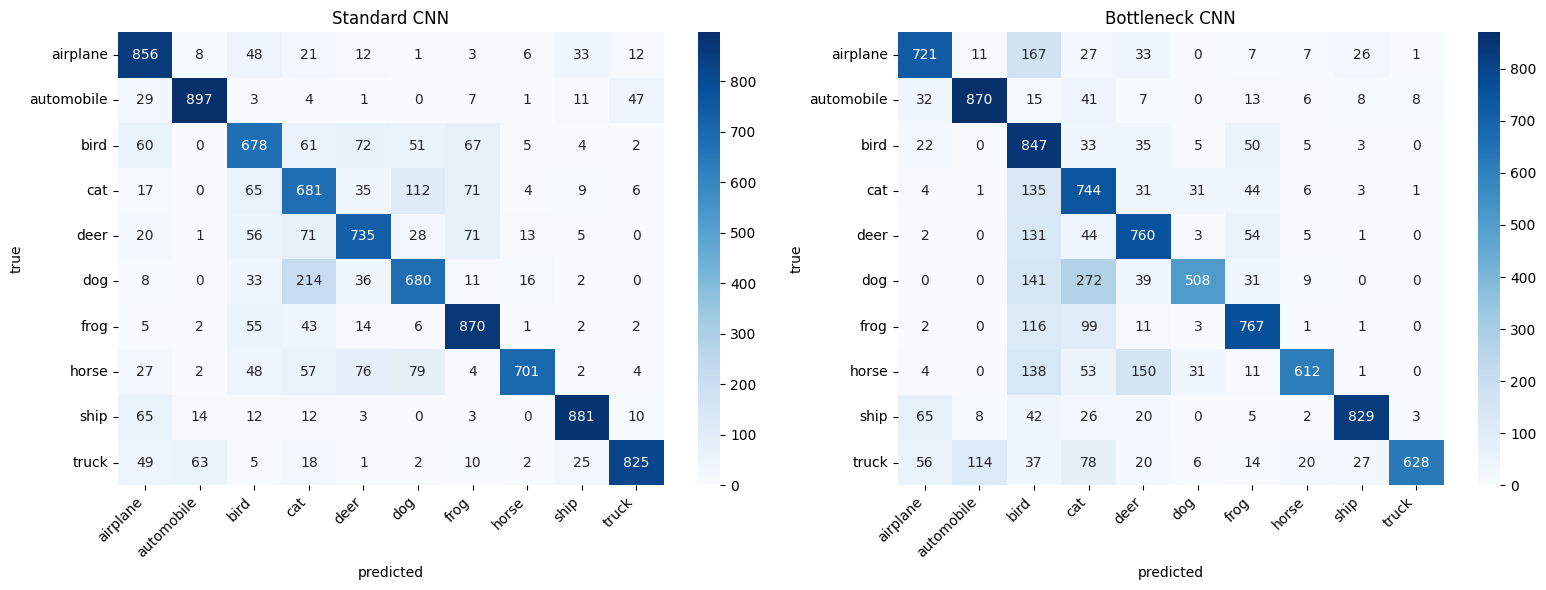

In [50]:
# Plot confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plt.subplot(1, 2, 1)
plot_confusion_matrix(standard_cnn, test_loader, device, CLASS_NAMES, 'Standard CNN')

plt.subplot(1, 2, 2)
plot_confusion_matrix(bottleneck_cnn, test_loader, device, CLASS_NAMES, 'Bottleneck CNN')

plt.tight_layout()
plt.show()

In [51]:
def visualize_predictions(model, dataset, device, class_names, num_samples=10):
    """
    Visualize model predictions on sample images.
    Shows correct predictions in green, incorrect in red.
    """
    # TODO: Implement prediction visualization
    model.eval()
    idxs = np.random.choice(len(dataset), size=num_samples, replace=False)
    fig, axes = plt.subplots(2, 5, figsize=(14, 6))
    axes = axes.flatten()

    mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
    std = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)

    for ax, idx in zip(axes, idxs):
        img, label = dataset[idx]
        x = img.unsqueeze(0).to(device)

        with torch.no_grad():
            out = model(x)
            pred = out.argmax(dim=1).item()

        # unnormalize for display
        img_show = (img * std + mean).clamp(0, 1)
        ax.imshow(img_show.permute(1, 2, 0))

        ok = (pred == label)
        color = 'green' if ok else 'red'  # vibe
        ax.set_title(f"t:{class_names[label]}\np:{class_names[pred]}", color=color, fontsize=10)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    #raise NotImplementedError()

Standard CNN Predictions:


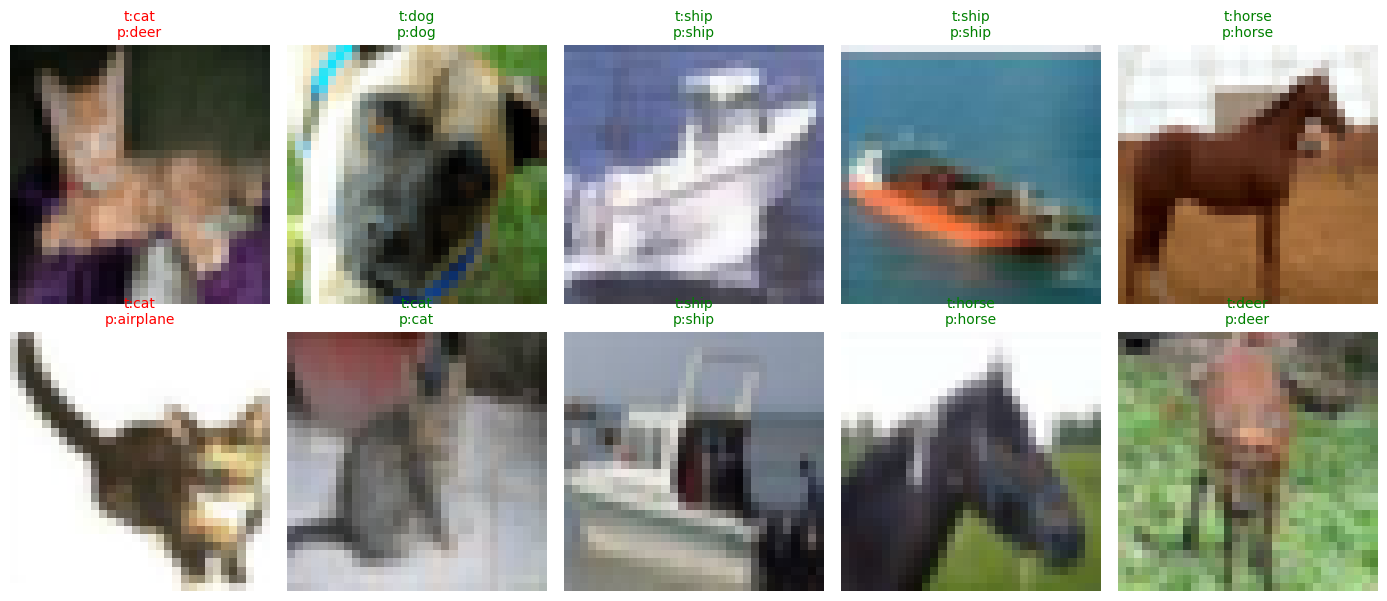


Bottleneck CNN Predictions:


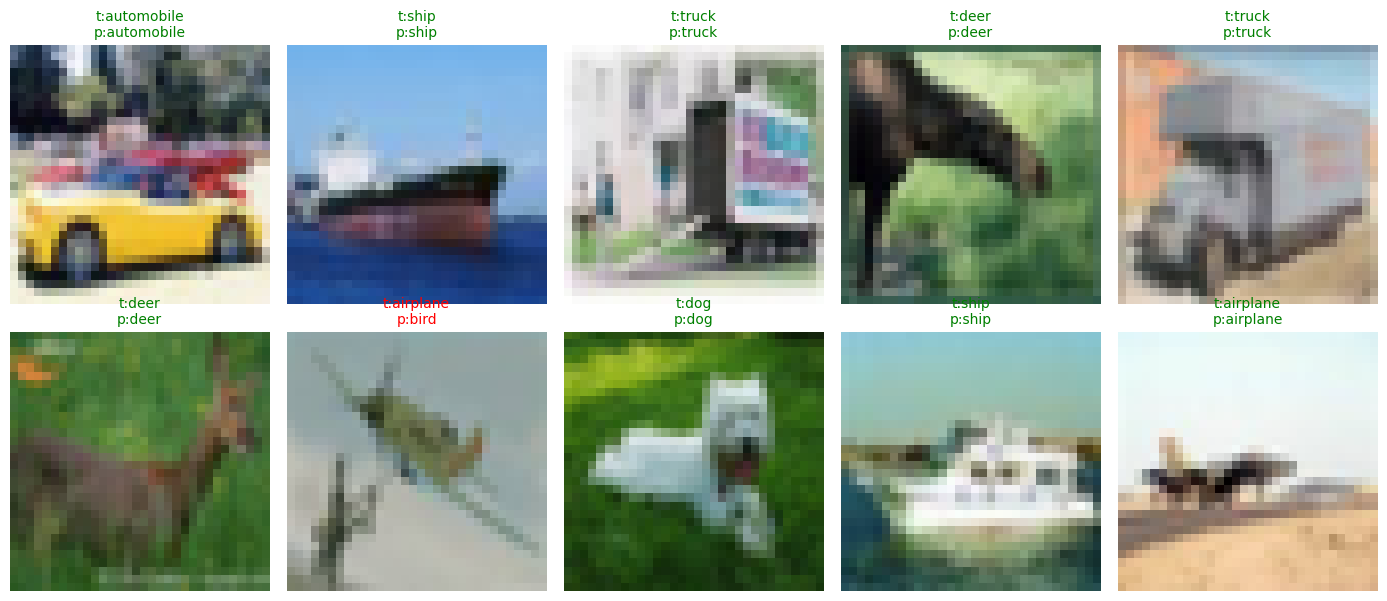

In [52]:
# Visualize predictions for both models
print("Standard CNN Predictions:")
visualize_predictions(standard_cnn, test_dataset, device, CLASS_NAMES)

print("\nBottleneck CNN Predictions:")
visualize_predictions(bottleneck_cnn, test_dataset, device, CLASS_NAMES)

## Part 9: Summary & Analysis (10 points)

In [53]:
# Summary statistics (provided)
print("="*60)
print("FINAL COMPARISON SUMMARY")
print("="*60)
print(f"{'Metric':<30} {'Standard CNN':<15} {'Bottleneck CNN':<15}")
print("-"*60)
print(f"{'Parameters':<30} {standard_params:,}" + " "*(15-len(f"{standard_params:,}")) + f"{bottleneck_params:,}")
print(f"{'Final Test Accuracy (%)':<30} {standard_history['test_acc'][-1]:<15.2f} {bottleneck_history['test_acc'][-1]:<15.2f}")
print(f"{'Best Test Accuracy (%)':<30} {max(standard_history['test_acc']):<15.2f} {max(bottleneck_history['test_acc']):<15.2f}")

FINAL COMPARISON SUMMARY
Metric                         Standard CNN    Bottleneck CNN 
------------------------------------------------------------
Parameters                     620,810        121,866
Final Test Accuracy (%)        78.04           72.86          
Best Test Accuracy (%)         78.04           76.15          


### 📝 Analysis Questions

Answer the following questions:

**Question 1:** How do 1×1 convolutions in bottleneck blocks reduce the parameter count? Show a calculation example.

**Question 2:** Compare the accuracy achieved by both models. Is the parameter reduction worth the potential accuracy trade-off?

**Question 3:** Looking at the confusion matrices, which classes are most often confused? Why might this be?

**Your Answers:**

*[Double-click to edit this cell and write your answers here]*

**Answer 1:** 1X 1 convolutions reduce parameters by shrinking the channel dimension before the expensive three by three step. a plain three by three conv that maps 64 channels to 64 channels uses 64 times 64 times 9 weights, which gives 36864 weights (ignoring bias). in a bottleneck block with reduction 4, you first reduce 64 channels down to 16 using a one by one conv: 64 times 16 gives 1024 weights. then the three by three runs in the smaller space: 16 times 16 times 9 gives 2304 weights. then you expand back using another one by one conv: 16 times 64 gives 1024 weights. total is 1024 plus 2304 plus 1024 which gives 4352 weights. so the bottleneck version uses far fewer parameters because the costly three by three happens on 16 channels instead of 64


**Answer 2:** the standard cnn achieved about 78.04 test accuracy, while the bottleneck cnn ended around 72.86 test accuracy, with a best point around 76.15 during training. the parameter count dropped from 620,810 to 121,866, which is about an eighty percent reduction. whether this is worth it depends on the goal. if you care about memory, speed, or deploying on limited hardware, the bottleneck model is a strong win because it is much smaller and still reasonably accurate. if maximum accuracy is the priority, the standard cnn is better here. also, your bottleneck training shows bigger swings in test accuracy and loss across epochs, so using early stopping at the best epoch would make the tradeoff look better


**Answer 3:** the most common confusions are between visually similar classes. for the standard cnn, cats and dogs are heavily confused both ways, and there is also confusion among deer and horse, plus some airplane and ship mixups. for the bottleneck cnn, these confusions are stronger: dogs are often predicted as cats, airplanes are often predicted as birds, and trucks often get predicted as automobiles. this happens because cifar images are low resolution and many classes share shapes, textures, and backgrounds. for example cats and dogs have similar fur and face patterns at 32 by 32, trucks and automobiles share wheels and body shapes, and airplanes versus birds both appear in sky like backgrounds with thin wing liek structures